In [14]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df=pd.read_csv("students.csv")
df

,Roll_No,Name,English,Maths,Science,Computer,Physics,Chemistry,Total,Percentage
0,1,Aarav Sharma,85,92,78,95,88,82,520,86.67
1,2,Priya Verma,90,88,94,96,85,91,544,90.67
2,3,Rahul Mehta,72,68,75,80,70,74,439,73.17
3,4,Ananya Singh,95,98,92,99,94,96,574,95.67
4,5,Rohan Gupta,65,72,68,75,70,66,416,69.33
5,6,Sneha Kapoor,88,85,90,92,87,89,531,88.50
6,7,Arjun Malhotra,78,82,75,88,80,77,480,80.00
7,8,Kavya Joshi,92,95,89,97,93,90,556,92.67
8,9,Aditya Jain,55,62,58,70,64,60,369,61.50
9,10,Ishita Rao,84,90,86,91,88,85,524,87.33


In [8]:
df.drop(columns=["Name","Roll_No"],inplace=True)
df

KeyError: "['Name', 'Roll_No'] not found in axis"

In [9]:
df

,English,Maths,Science,Computer,Physics,Chemistry,Total,Percentage
0,85,92,78,95,88,82,520,86.67
1,90,88,94,96,85,91,544,90.67
2,72,68,75,80,70,74,439,73.17
3,95,98,92,99,94,96,574,95.67
4,65,72,68,75,70,66,416,69.33
5,88,85,90,92,87,89,531,88.50
6,78,82,75,88,80,77,480,80.00
7,92,95,89,97,93,90,556,92.67
8,55,62,58,70,64,60,369,61.50
9,84,90,86,91,88,85,524,87.33


In [10]:
df.var()

English        164.656410
Maths          137.628205
Science        151.101923
Computer       106.148077
Physics        118.917308
Chemistry      132.353205
Total         4676.266667
Percentage     129.917728
dtype: float64

In [11]:
df.cov()

,English,Maths,Science,Computer,Physics,Chemistry,Total,Percentage
English,164.656410,145.256410,150.361538,130.889744,137.376923,144.453846,872.994872,145.511282
Maths,145.256410,137.628205,130.083333,117.339744,124.660256,127.955128,782.923077,130.497179
Science,150.361538,130.083333,151.101923,119.014744,124.098077,137.348077,812.007692,135.346410
Computer,130.889744,117.339744,119.014744,106.148077,109.898077,114.660897,697.951282,116.335385
Physics,137.376923,124.660256,124.098077,109.898077,118.917308,119.333974,734.284615,122.390256
Chemistry,144.453846,127.955128,137.348077,114.660897,119.333974,132.353205,776.105128,129.361538
Total,872.994872,782.923077,812.007692,697.951282,734.284615,776.105128,4676.266667,779.442051
Percentage,145.511282,130.497179,135.346410,116.335385,122.390256,129.361538,779.442051,129.917728


In [13]:
corr=df.corr()
corr

,English,Maths,Science,Computer,Physics,Chemistry,Total,Percentage
English,1.000000,0.964922,0.953262,0.990057,0.981752,0.978526,0.994885,0.994886
Maths,0.964922,1.000000,0.902055,0.970812,0.974432,0.948062,0.975923,0.975918
Science,0.953262,0.902055,1.000000,0.939744,0.925779,0.971226,0.965996,0.966001
Computer,0.990057,0.970812,0.939744,1.000000,0.978164,0.967369,0.990648,0.990653
Physics,0.981752,0.974432,0.925779,0.978164,1.000000,0.951205,0.984674,0.984669
Chemistry,0.978526,0.948062,0.971226,0.967369,0.951205,1.000000,0.986515,0.986515
Total,0.994885,0.975923,0.965996,0.990648,0.984674,0.986515,1.000000,1.000000
Percentage,0.994886,0.975918,0.966001,0.990653,0.984669,0.986515,1.000000,1.000000


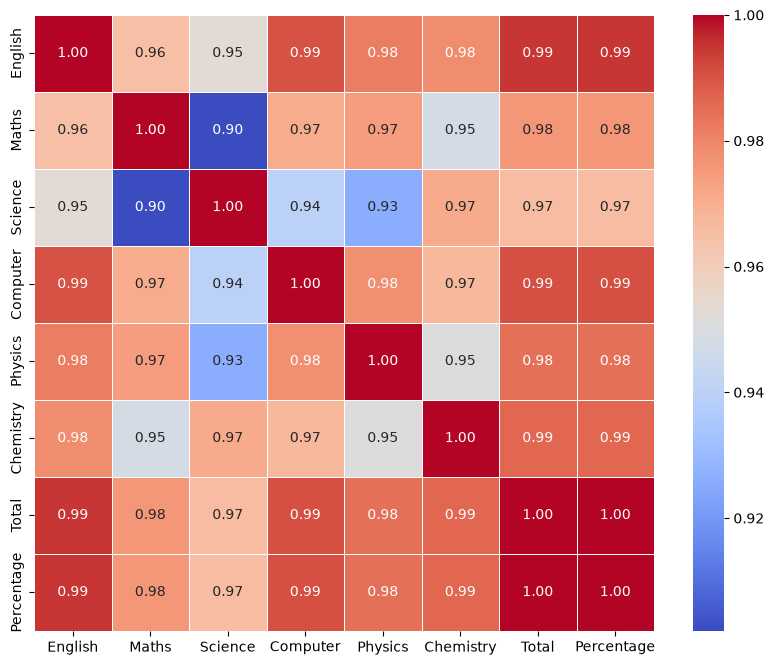

In [16]:
plt.figure(figsize=(10,8))
sns.heatmap(corr,annot=True,cmap='coolwarm',fmt=".2f",linewidth=0.5)
plt.show()


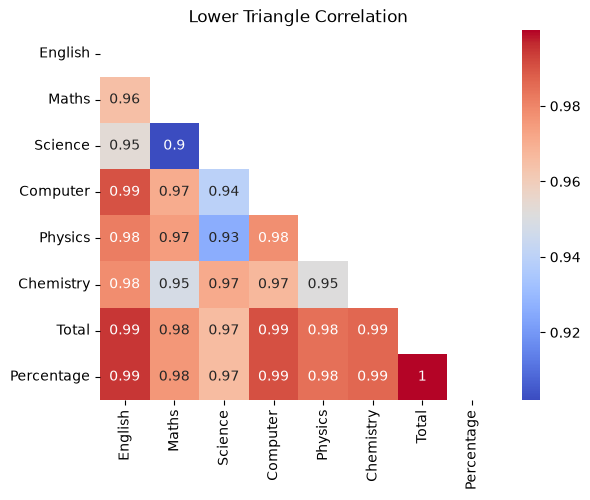

In [19]:
mask_upper = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(corr, annot=True, cmap="coolwarm", mask=mask_upper)

plt.title("Lower Triangle Correlation")
plt.show()

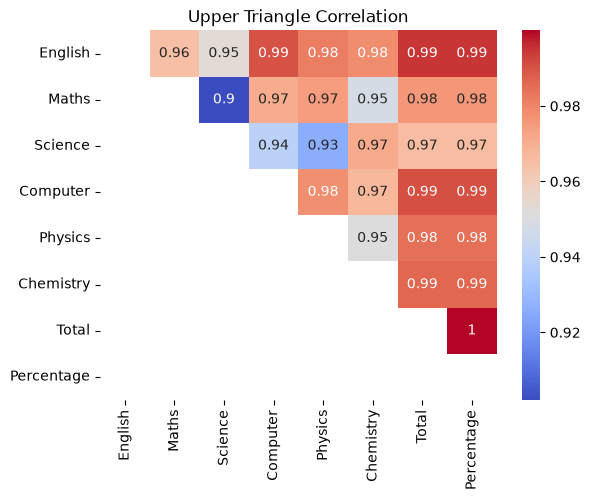

In [20]:
mask_lower = np.tril(np.ones_like(corr, dtype=bool))

sns.heatmap(corr, annot=True, cmap="coolwarm", mask=mask_lower)

plt.title("Upper Triangle Correlation")
plt.show()

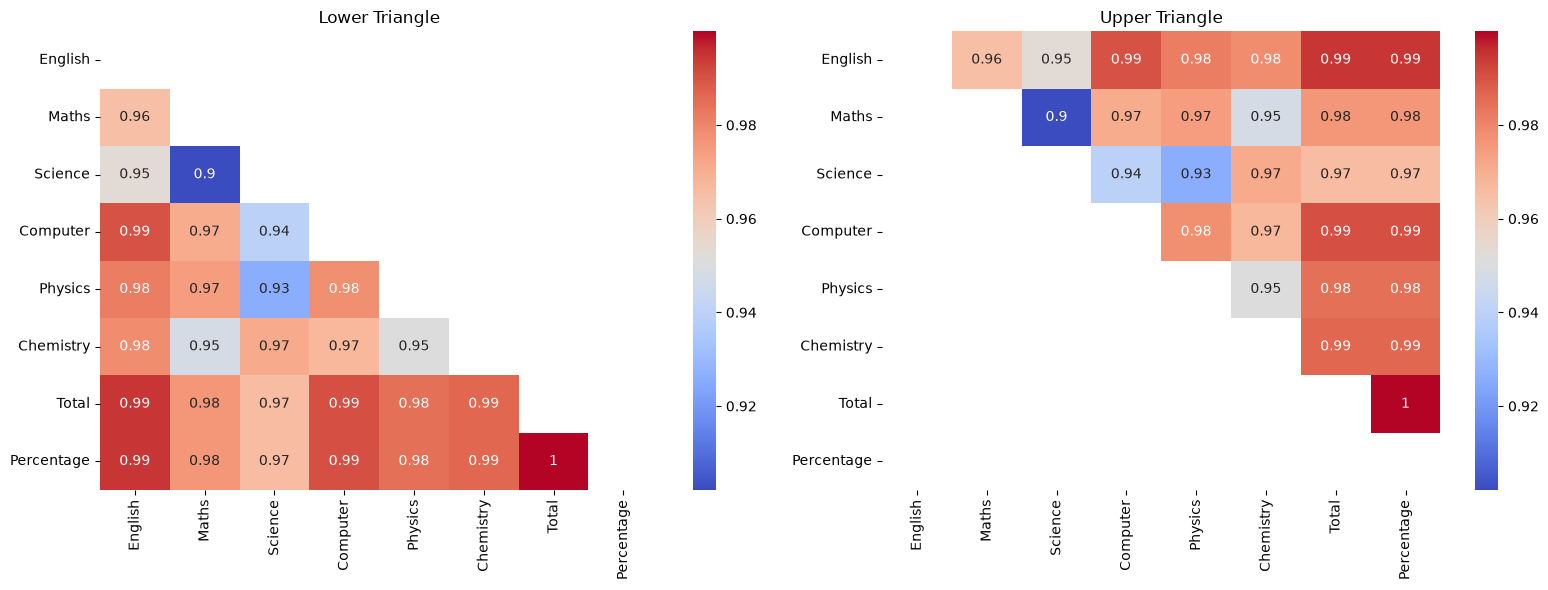

In [21]:

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Upper triangle only
mask_upper = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, cmap="coolwarm",
            mask=mask_upper, ax=axes[0])
axes[0].set_title("Lower Triangle")

# Lower triangle only
mask_lower = np.tril(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, cmap="coolwarm",
            mask=mask_lower, ax=axes[1])
axes[1].set_title("Upper Triangle")

plt.tight_layout()
plt.show()


In [22]:
from sklearn.preprocessing import MinMaxScaler

# 1. Initialize the scaler
scaler = MinMaxScaler()

# 2. Fit to data and transform (scales each feature to the range [0, 1])
data = scaler.fit_transform(df)

# 3. (Recommended) Convert the resulting NumPy array back to a DataFrame with column names
df_scaled = pd.DataFrame(data, columns=df.columns)
df_scaled.head()

,English,Maths,Science,Computer,Physics,Chemistry,Total,Percentage
0,0.727273,0.85,0.500,0.882353,0.800000,0.609756,0.736607,0.736673
1,0.840909,0.75,0.900,0.911765,0.714286,0.829268,0.843750,0.843825
2,0.431818,0.25,0.425,0.441176,0.285714,0.414634,0.375000,0.375033
3,0.954545,1.00,0.850,1.000000,0.971429,0.951220,0.977679,0.977766
4,0.272727,0.35,0.250,0.294118,0.285714,0.219512,0.272321,0.272167


In [27]:
pca=PCA(n_components=1)
df=pca.fit_transform(df)
df

array([[  34.08960284],
       [  60.50617435],
       [ -54.27505822],
       [  93.23689152],
       [ -79.48956066],
       [  46.28598881],
       [  -9.58053626],
       [  73.53985535],
       [-130.95495135],
       [  38.55202882],
       [ -25.86816808],
       [  92.22279077],
       [ -56.51693519],
       [  56.06481328],
       [-105.77162526],
       [  30.97351838],
       [ -21.51205651],
       [  83.41562339],
       [-122.06992963],
       [  50.64847573],
       [ -10.5770086 ],
       [  68.10497866],
       [ -66.31656143],
       [  47.37835133],
       [-102.46594319],
       [  85.61852954],
       [ -52.18604248],
       [  57.1756074 ],
       [-146.14657638],
       [  74.68049537],
       [ -19.38774034],
       [  49.48346886],
       [ -86.00423545],
       [  98.75790027],
       [ -40.10591217],
       [  62.63646543],
       [-127.56255941],
       [  73.58375577],
       [ -68.56256825],
       [  48.39865299]])